## Aim 7. To perform an analyze of Ensemble Technique


## 1. Importing the libraries

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier


## 2. Install KaggleHub Library


In [3]:
!pip install kagglehub

Defaulting to user installation because normal site-packages is not writeable


## 3.Download Dataset from Kaggle

In [4]:
# Load Breast Cancer dataset
cancer = load_breast_cancer()

# Convert into a pandas DataFrame
df_cancer = pd.DataFrame(cancer.data, columns=cancer.feature_names)
df_cancer['target'] = cancer.target

print(df_cancer.head())

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
0             

## 4.Exploratory Data analysis (EDA)

In [5]:
# Check dataset info and missing values
print(df_cancer.info())

print("\nMissing Values:")
print(df_cancer.isnull().sum())

# Check target class distribution (0 = Malignant, 1 = Benign)
print("\nTarget Class Distribution:")
print(df_cancer['target'].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

## 5.Train-Test splits

In [6]:
X = df_cancer.drop(columns=['target'])
y = df_cancer['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

Training set shape: (455, 30)
Testing set shape: (114, 30)


## 6.Feature Scaling

In [7]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 7.Train Individual Models and Voting Classifier Ensemble

In [9]:
# Initialize individual base models
clf1 = LogisticRegression(random_state=42)
clf2 = DecisionTreeClassifier(random_state=42)
clf3 = KNeighborsClassifier()

# Initialize Voting Classifier (combining them)
ensemble_model = VotingClassifier(
    estimators=[('lr', clf1), ('dt', clf2), ('knn', clf3)],
    voting='hard'
)

# Train the base models and the ensemble model
clf1.fit(X_train_scaled, y_train)
clf2.fit(X_train_scaled, y_train)
clf3.fit(X_train_scaled, y_train)
ensemble_model.fit(X_train_scaled, y_train)

,estimators,"[('lr', ...), ('dt', ...), ...]"
,voting,'hard'
,weights,None
,n_jobs,None
,flatten_transform,True
,verbose,False
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True


## 8.Model Evaluation and comparisons


--- Logistic Regression ---
Accuracy: 0.9737
Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.95      0.96        43
           1       0.97      0.99      0.98        71

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114


--- Decision Tree ---
Accuracy: 0.9474
Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.93      0.93        43
           1       0.96      0.96      0.96        71

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114


--- K-Nearest Neighbors ---
Accuracy: 0.9474
Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.93      0.93        43
           1       0.96      0.96   

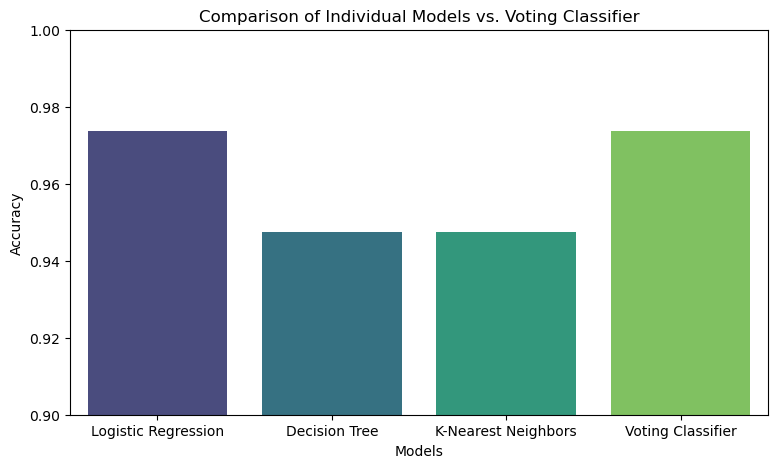

In [12]:
# Evaluate individual models and the ensemble
models = {
    'Logistic Regression': clf1,
    'Decision Tree': clf2,
    'K-Nearest Neighbors': clf3,
    'Voting Classifier': ensemble_model
}

accuracies = {}

for name, model in models.items():
    y_pred = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    accuracies[name] = acc
    print(f"\n--- {name} ---")
    print(f"Accuracy: {acc:.4f}")
    print("Classification Report:")
    print(classification_report(y_test, y_pred))

# Plot performance comparison
plt.figure(figsize=(9, 5))
sns.barplot(x=list(accuracies.keys()), y=list(accuracies.values()), hue=list(accuracies.keys()), palette='viridis', legend=False)
plt.title('Comparison of Individual Models vs. Voting Classifier')
plt.xlabel('Models')
plt.ylabel('Accuracy')
plt.ylim(0.90, 1.0)
plt.show()


## 9.Confusion Matrix Visualization (Voting Classifier)

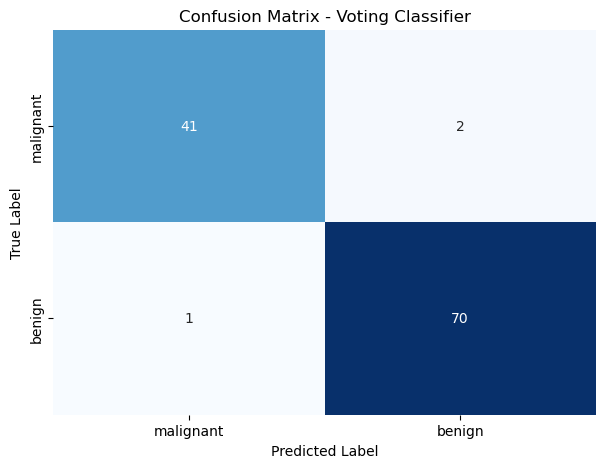

In [14]:
# Predict using the Voting Classifier
y_pred_ensemble = ensemble_model.predict(X_test_scaled)
cm = confusion_matrix(y_test, y_pred_ensemble)

# Plot confusion matrix
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=cancer.target_names,
            yticklabels=cancer.target_names)
plt.title('Confusion Matrix - Voting Classifier')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()